In [5]:
from statsbombpy import sb      # sb = a toolbox of download functions
import pandas as pd             # pd = tables ("DataFrames") in Python
import warnings
warnings.filterwarnings("ignore")   # hides the harmless "no credentials" warning

In [6]:
comps = sb.competitions()
comps[comps.competition_name == "Premier League"][["competition_id", "season_id", "season_name"]]

,competition_id,season_id,season_name
68,2,27,2015/2016
69,2,44,2003/2004


In [7]:
matches = sb.matches(competition_id=2, season_id=27)
print(len(matches), "matches")
matches[["match_id", "match_date", "home_team", "away_team", "home_score", "away_score"]].head()

380 matches


,match_id,match_date,home_team,away_team,home_score,away_score
0,3754217,2015-09-19,Chelsea,Arsenal,2,0
1,3754117,2015-12-13,Aston Villa,Arsenal,0,2
2,3754296,2015-12-21,Arsenal,Manchester City,2,1
3,3753983,2015-10-31,Swansea City,Arsenal,0,3
4,3754160,2015-12-05,Arsenal,Sunderland,3,1


In [8]:
mid = matches[matches.home_team == "Leicester City"].iloc[0].match_id   # .iloc[0] = first row
ev = sb.events(match_id=mid)
print(len(ev), "events,", len(ev.columns), "columns")
ev["type"].value_counts().head(12)            # how many of each event type

3576 events, 90 columns


type
Pass             1002
Ball Receipt*     924
Carry             742
Pressure          363
Ball Recovery     102
Duel               83
Clearance          59
Block              42
Goal Keeper        35
Miscontrol         34
Dribble            31
Dispossessed       29
Name: count, dtype: int64

In [9]:
cols = ["minute", "second", "team", "player", "type", "location", "under_pressure"]
ev[cols].iloc[100:130]          # rows 100 to 129

,minute,second,team,player,type,location,under_pressure
100,6,29,AFC Bournemouth,Simon Francis,Pass,"[50.9, 76.1]",NaN
101,6,52,Leicester City,Kasper Schmeichel,Pass,"[15.5, 44.9]",NaN
102,6,58,AFC Bournemouth,Steve Cook,Pass,"[27.4, 15.6]",NaN
103,7,1,AFC Bournemouth,Artur Boruc,Pass,"[11.0, 42.9]",NaN
104,7,6,AFC Bournemouth,Adam Smith,Pass,"[43.5, 78.2]",NaN
105,7,30,Leicester City,Kasper Schmeichel,Pass,"[13.1, 26.9]",NaN
106,7,32,AFC Bournemouth,Harry Arter,Pass,"[53.1, 23.7]",NaN
107,7,34,AFC Bournemouth,Andrew Surman,Pass,"[44.3, 29.3]",True
108,7,39,Leicester City,Wes Morgan,Pass,"[38.6, 42.3]",NaN
109,7,42,Leicester City,Kasper Schmeichel,Pass,"[11.4, 42.5]",NaN


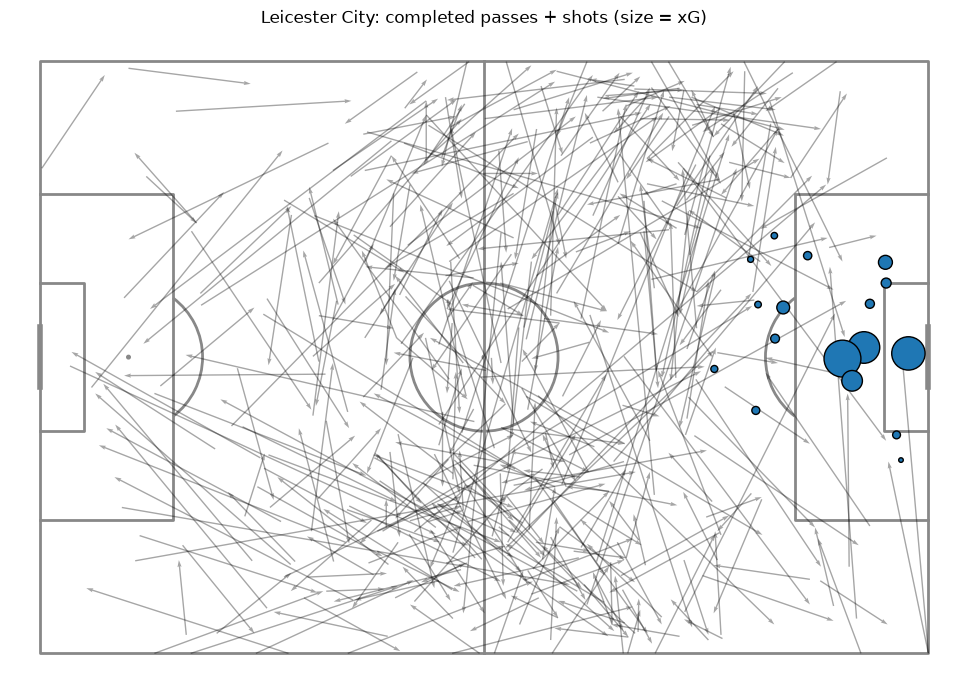

In [10]:
import matplotlib.pyplot as plt
from mplsoccer import Pitch

team   = ev.team.iloc[0]
passes = ev[(ev.type == "Pass") & (ev.team == team)]     # & = AND; each side needs brackets
done   = passes[passes.pass_outcome.isna()]               # completed passes only
shots  = ev[(ev.type == "Shot") & (ev.team == team)]

pitch = Pitch(pitch_type="statsbomb", line_color="#888")
fig, ax = pitch.draw(figsize=(10, 7))
pitch.arrows(done.location.str[0], done.location.str[1],          # .str[0] = first item of each [x, y]
             done.pass_end_location.str[0], done.pass_end_location.str[1],
             ax=ax, width=1, alpha=0.35)
pitch.scatter(shots.location.str[0], shots.location.str[1],
              s=shots.shot_statsbomb_xg * 900, ax=ax, edgecolors="black")
ax.set_title(f"{team}: completed passes + shots (size = xG)")
plt.show()

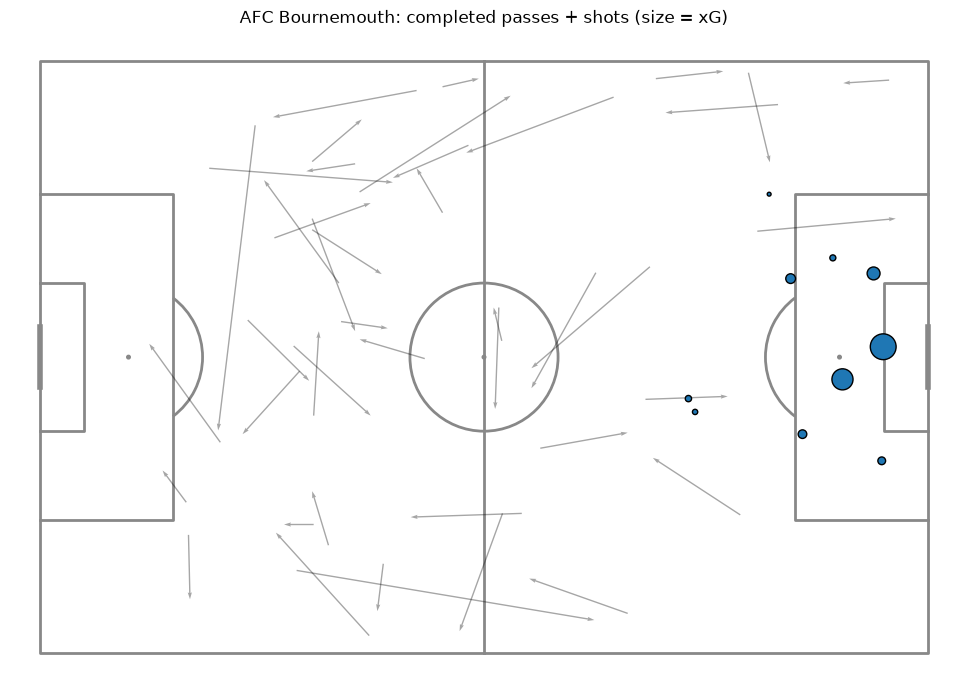

In [11]:
import matplotlib.pyplot as plt
from mplsoccer import Pitch

team   = ev.team.unique()[1]
passes = ev[(ev.type == "Pass") & (ev.team == team) & (ev.under_pressure == True)]    # & = AND; each side needs brackets
done   = passes[passes.pass_outcome.isna()]               # completed passes only
shots  = ev[(ev.type == "Shot") & (ev.team == team)]

pitch = Pitch(pitch_type="statsbomb", line_color="#888")
fig, ax = pitch.draw(figsize=(10, 7))
pitch.arrows(done.location.str[0], done.location.str[1],          # .str[0] = first item of each [x, y]
             done.pass_end_location.str[0], done.pass_end_location.str[1],
             ax=ax, width=1, alpha=0.35)
pitch.scatter(shots.location.str[0], shots.location.str[1],
              s=shots.shot_statsbomb_xg * 900, ax=ax, edgecolors="black")
ax.set_title(f"{team}: completed passes + shots (size = xG)")
plt.show()

away: 370 passes (real avg 469), completion 0.78 (real 0.75)
home: 496 passes (real avg 469), completion 0.73 (real 0.75)


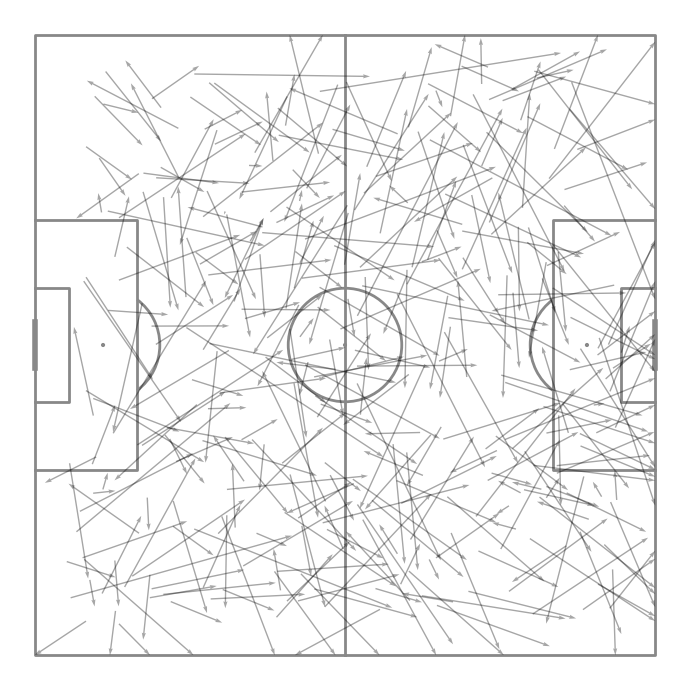

In [12]:
import json, pandas as pd
from mplsoccer import Pitch

fake = pd.read_json("data/synthetic/match_seed42.json")
cal  = json.load(open("engine/calibration.json"))["per_team_per_match"]
for side, g in fake[fake.kind == "pass"].groupby("team"):
    print(f"{side}: {len(g)} passes (real avg {cal['passes']['mean']:.0f}), "
          f"completion {g.success.mean():.2f} (real {cal['pass_completion']['mean']:.2f})")

home = fake[(fake.kind == "pass") & (fake.team == "home") & fake.success]
pitch = Pitch(pitch_type="custom", pitch_length=100, pitch_width=100, line_color="#888")
fig, ax = pitch.draw(figsize=(10, 7))
pitch.arrows(home.x, home.y, home.end_x, home.end_y, ax=ax, width=1, alpha=0.35)

away: 418 passes (real avg 469), completion 0.72 (real 0.75)
home: 477 passes (real avg 469), completion 0.76 (real 0.75)


team
away    0.467039
home    0.532961
dtype: float64

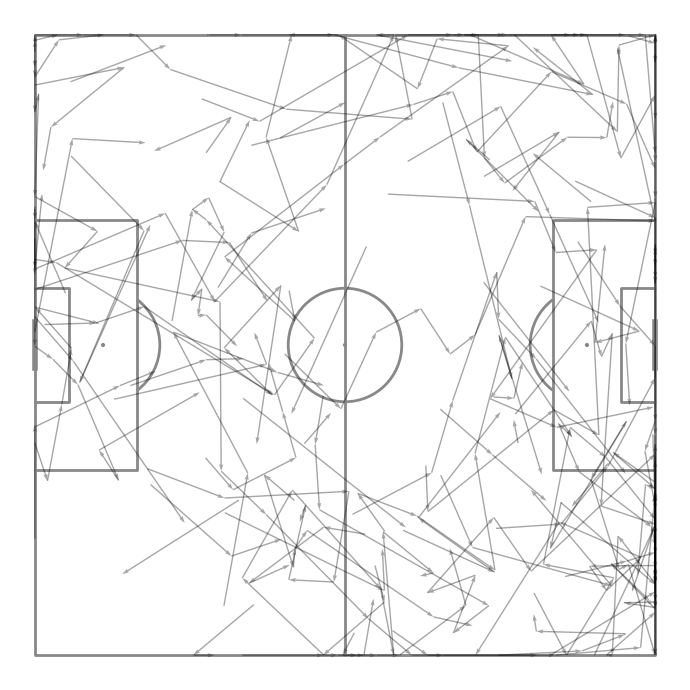

In [14]:
import json, pandas as pd
from mplsoccer import Pitch

fake = pd.read_json("data/synthetic/match_seed42.json")
cal  = json.load(open("engine/calibration.json"))["per_team_per_match"]
for side, g in fake[fake.kind == "pass"].groupby("team"):
    print(f"{side}: {len(g)} passes (real avg {cal['passes']['mean']:.0f}), "
          f"completion {g.success.mean():.2f} (real {cal['pass_completion']['mean']:.2f})")

home = fake[(fake.kind == "pass") & (fake.team == "home") & fake.success]
pitch = Pitch(pitch_type="custom", pitch_length=100, pitch_width=100, line_color="#888")
fig, ax = pitch.draw(figsize=(10, 7))
pitch.arrows(home.x, home.y, home.end_x, home.end_y, ax=ax, width=1, alpha=0.35)
fake[fake.kind == "pass"].groupby("team").size() / (fake.kind == "pass").sum()

away: 418 passes (real avg 469), completion 0.72 (real 0.75)
home: 477 passes (real avg 469), completion 0.76 (real 0.75)


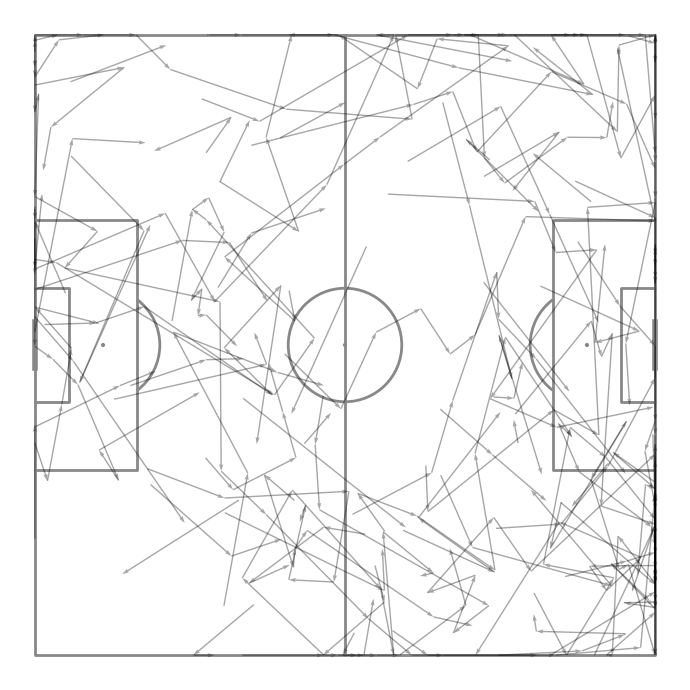

In [15]:
import json, pandas as pd
from mplsoccer import Pitch

fake = pd.read_json("data/synthetic/match_seed42.json")
cal  = json.load(open("engine/calibration.json"))["per_team_per_match"]
for side, g in fake[fake.kind == "pass"].groupby("team"):
    print(f"{side}: {len(g)} passes (real avg {cal['passes']['mean']:.0f}), "
          f"completion {g.success.mean():.2f} (real {cal['pass_completion']['mean']:.2f})")

home = fake[(fake.kind == "pass") & (fake.team == "home") & fake.success]
pitch = Pitch(pitch_type="custom", pitch_length=100, pitch_width=100, line_color="#888")
fig, ax = pitch.draw(figsize=(10, 7))
pitch.arrows(home.x, home.y, home.end_x, home.end_y, ax=ax, width=1, alpha=0.35)